# 02 · Extracción de rasgos, PCA y K-Means
**Sistema de apoyo para detección de tumores cerebrales en resonancia magnética**

Entrenar una red completa en CPU con cada modelo sería muy lento. Por eso cada imagen se convierte **una sola vez** en números:
- **Rasgos de MobileNetV2** (red preentrenada con ImageNet, congelada): 1,280 valores por imagen.
- **Rasgos básicos:** brillo, contraste e histograma de grises de 16 barras (18 valores). Son la base de la solución más simple.

Todas las imágenes pasan por el mismo preprocesamiento de `app/backend/ml/preprocesar.py`: recorte del cerebro → 160 × 160 → RGB de 0 a 255. La normalización de MobileNetV2 está dentro del modelo.

Los rasgos se guardan en `datos/rasgos/` en el **mismo orden que el manifiesto**, junto con una **firma** calculada con el manifiesto (rutas y SHA-256 de cada imagen), el tamaño de imagen y el código de preprocesamiento. Si ya existen y la firma coincide, solo se leen; si cambió el manifiesto o el preprocesamiento, se recalculan.

Extraer rasgos con una red congelada no usa las etiquetas, así que hacerlo para todas las imágenes (incluida la prueba) no filtra información. El PCA y el K-Means de este notebook se ajustan **solo con el entrenamiento**.

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from app.backend.ml import config, rasgos
from app.backend.ml.preprocesar import cargar_lote

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
config.RASGOS.mkdir(parents=True, exist_ok=True)
INICIO = time.time()

man = pd.read_csv(config.MANIFIESTO)
print(f"Manifiesto: {len(man):,} imágenes")
display(pd.crosstab(man.clase, man.particion, margins=True, margins_name="total"))

Manifiesto: 3,600 imágenes


particion,entrenamiento,prueba,total
clase,,,
glioma,1166,291,1457
meningioma,655,164,819
notumor,294,73,367
pituitary,765,192,957
total,2880,720,3600


## 1. Extracción (una sola vez)

In [2]:
RUTA_MOBILENET = config.RASGOS / "rasgos_mobilenet.npz"
RUTA_BASICOS = config.RASGOS / "rasgos_basicos.npz"
RUTA_IMAGENES = config.RASGOS / "imagenes_160.npy"   # imágenes preparadas, para el ajuste fino del notebook 04
rutas = man.ruta.to_numpy().astype(str)


RUTA_FIRMA_IMAGENES = config.RASGOS / "imagenes_160.firma.txt"
FIRMA = rasgos.firma_cache(man)
print("Firma del manifiesto + preprocesamiento:", FIRMA[:16], "…")


def vigente(ruta_npz):
    """El archivo existe, tiene la misma firma y sus rutas son las del manifiesto en el mismo orden."""
    if not ruta_npz.exists():
        return False
    with np.load(ruta_npz, allow_pickle=False) as d:
        return ("firma" in d.files and str(d["firma"]) == FIRMA
                and len(d["rutas"]) == len(rutas) and bool((d["rutas"] == rutas).all()))


imagenes_vigentes = (RUTA_IMAGENES.exists() and RUTA_FIRMA_IMAGENES.exists()
                     and RUTA_FIRMA_IMAGENES.read_text(encoding="utf-8").strip() == FIRMA)
if vigente(RUTA_MOBILENET) and vigente(RUTA_BASICOS) and imagenes_vigentes:
    print("Los rasgos ya existen y su firma coincide con el manifiesto y el preprocesamiento actuales: se leen del disco.")
else:
    print("No hay rasgos guardados para este manifiesto y este preprocesamiento: se calculan.")
    t0 = time.time()
    imagenes = cargar_lote([config.RAIZ / r for r in rutas], hilos=12)
    print(f"Imágenes preparadas: {imagenes.shape} {imagenes.dtype} en {time.time() - t0:.0f} s")
    np.save(RUTA_IMAGENES, imagenes)
    RUTA_FIRMA_IMAGENES.write_text(FIRMA, encoding="utf-8")

    t0 = time.time()
    X_basicos = rasgos.rasgos_basicos_lote(imagenes)
    np.savez_compressed(RUTA_BASICOS, X=X_basicos, rutas=rutas, nombres=np.array(rasgos.NOMBRES_BASICOS), firma=np.array(FIRMA))
    print(f"Rasgos básicos: {X_basicos.shape} en {time.time() - t0:.0f} s")

    t0 = time.time()
    X_mobilenet = rasgos.rasgos_mobilenet(imagenes)
    np.savez_compressed(RUTA_MOBILENET, X=X_mobilenet, rutas=rutas, firma=np.array(FIRMA))
    print(f"Rasgos MobileNetV2: {X_mobilenet.shape} en {time.time() - t0:.0f} s")
    del imagenes

with np.load(RUTA_MOBILENET, allow_pickle=False) as d:
    X = d["X"]
with np.load(RUTA_BASICOS, allow_pickle=False) as d:
    Xb = d["X"]
print("MobileNetV2:", X.shape, "· básicos:", Xb.shape, "· valores no finitos:", int((~np.isfinite(X)).sum() + (~np.isfinite(Xb)).sum()))
display(pd.DataFrame(Xb, columns=rasgos.NOMBRES_BASICOS).describe().T.round(4))

Firma del manifiesto + preprocesamiento: b2c9d71d55da7d41 …
Los rasgos ya existen y su firma coincide con el manifiesto y el preprocesamiento actuales: se leen del disco.


MobileNetV2: (3600, 1280) · básicos: (3600, 18) · valores no finitos: 0


,count,mean,std,min,25%,50%,75%,max
brillo,3600.0,0.2514,0.0588,0.1096,0.2146,0.2398,0.2713,0.6021
contraste,3600.0,0.1595,0.0420,0.0260,0.1370,0.1544,0.1737,0.3561
hist_00,3600.0,0.1786,0.0625,0.0000,0.1467,0.1844,0.2177,0.4962
hist_01,3600.0,0.0601,0.0326,0.0000,0.0408,0.0548,0.0732,0.3946
hist_02,3600.0,0.1002,0.0711,0.0000,0.0610,0.0858,0.1165,0.6692
hist_03,3600.0,0.1789,0.1114,0.0053,0.1072,0.1522,0.2240,0.7062
hist_04,3600.0,0.1864,0.0867,0.0027,0.1247,0.1918,0.2461,0.5480
hist_05,3600.0,0.1122,0.0704,0.0008,0.0555,0.0940,0.1646,0.4675
hist_06,3600.0,0.0600,0.0465,0.0004,0.0336,0.0470,0.0677,0.4098
hist_07,3600.0,0.0399,0.0326,0.0000,0.0223,0.0328,0.0457,0.3871


## 2. PCA: ¿se separan las clases?
Se estandarizan los 1,280 rasgos y se resumen con PCA, **ajustando solo con el entrenamiento**. Si las clases se separan en dos dimensiones, un modelo sencillo sobre estos rasgos debería funcionar bien.

Varianza explicada: componente 1 = 6.4%, componente 2 = 4.5%
Acumulada con 2 componentes: 10.9% · con 10: 28.3% · con 50: 51.7%


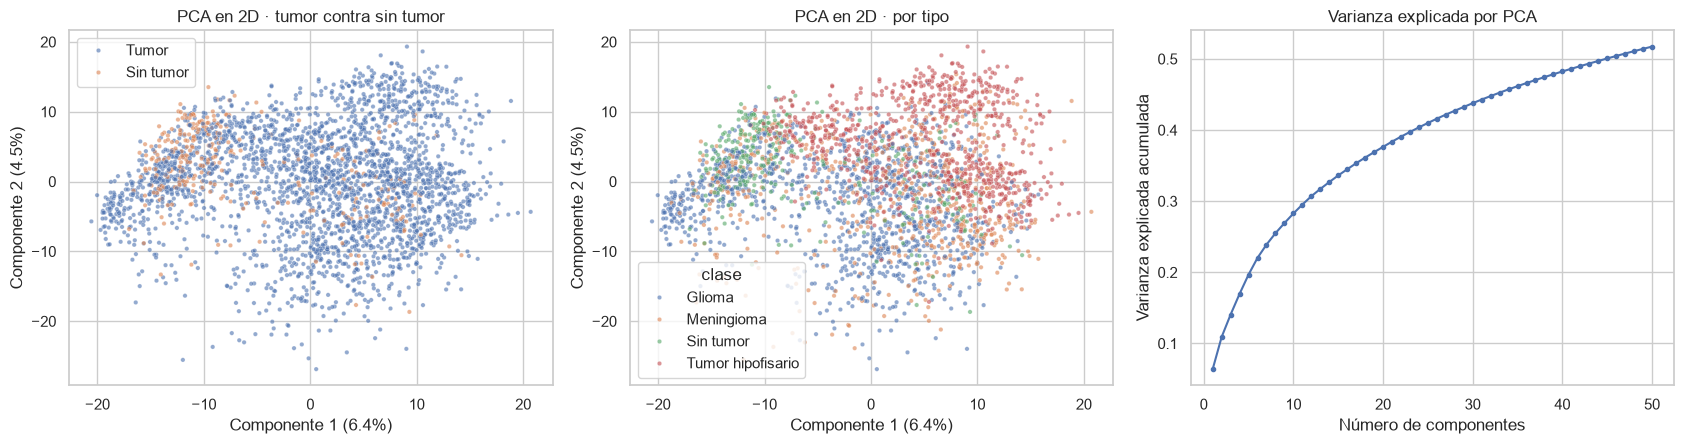

In [3]:
ent = (man.particion == "entrenamiento").to_numpy()
man_ent = man[ent].reset_index(drop=True)
escala = StandardScaler().fit(X[ent])
pca = PCA(n_components=50, random_state=config.SEMILLA).fit(escala.transform(X[ent]))
Z = pca.transform(escala.transform(X[ent]))
acumulada = np.cumsum(pca.explained_variance_ratio_)
print(f"Varianza explicada: componente 1 = {pca.explained_variance_ratio_[0]:.1%}, componente 2 = {pca.explained_variance_ratio_[1]:.1%}")
print(f"Acumulada con 2 componentes: {acumulada[1]:.1%} · con 10: {acumulada[9]:.1%} · con 50: {acumulada[49]:.1%}")

binaria = np.where(man_ent.es_tumor == 1, "Tumor", "Sin tumor")
nombres = man_ent.clase.map(config.NOMBRES_ES)
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=binaria, hue_order=["Tumor", "Sin tumor"], s=10, alpha=0.6, ax=axs[0])
axs[0].set_title("PCA en 2D · tumor contra sin tumor")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=nombres, hue_order=[config.NOMBRES_ES[c] for c in config.CLASES], s=10, alpha=0.6, ax=axs[1])
axs[1].set_title("PCA en 2D · por tipo")
for ax in axs[:2]:
    ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%})")
axs[2].plot(range(1, 51), acumulada, marker="o", ms=3)
axs[2].set_xlabel("Número de componentes"); axs[2].set_ylabel("Varianza explicada acumulada"); axs[2].set_title("Varianza explicada por PCA")
plt.tight_layout(); plt.savefig(FIGURAS / "rasgos_01_pca.png", dpi=130); plt.show()
pd.DataFrame({"componente": range(1, 51), "varianza": pca.explained_variance_ratio_, "acumulada": acumulada}).to_csv(
    config.RESULTADOS / "pca_varianza.csv", index=False)

## 3. K-Means: ¿aparecen las clases sin usar etiquetas?
K-Means agrupa las imágenes solo por parecido (sobre los 50 componentes de PCA). Se prueba con 2 grupos (contra tumor / sin tumor) y con 4 grupos (contra las 4 clases).

El **índice de Rand ajustado** compara los grupos con las clases reales: 1 = idénticos, 0 = como al azar.

grupo K-Means (k=2),0,1
clase real,,
Sin tumor,210,84
Tumor,885,1701


Índice de Rand ajustado (k=2 contra tumor / sin tumor): 0.073


grupo K-Means (k=4),0,1,2,3
clase real,,,,
Glioma,34,416,418,298
Meningioma,58,161,263,173
Sin tumor,11,200,60,23
Tumor hipofisario,198,30,268,269


Índice de Rand ajustado (k=4 contra las 4 clases): 0.058


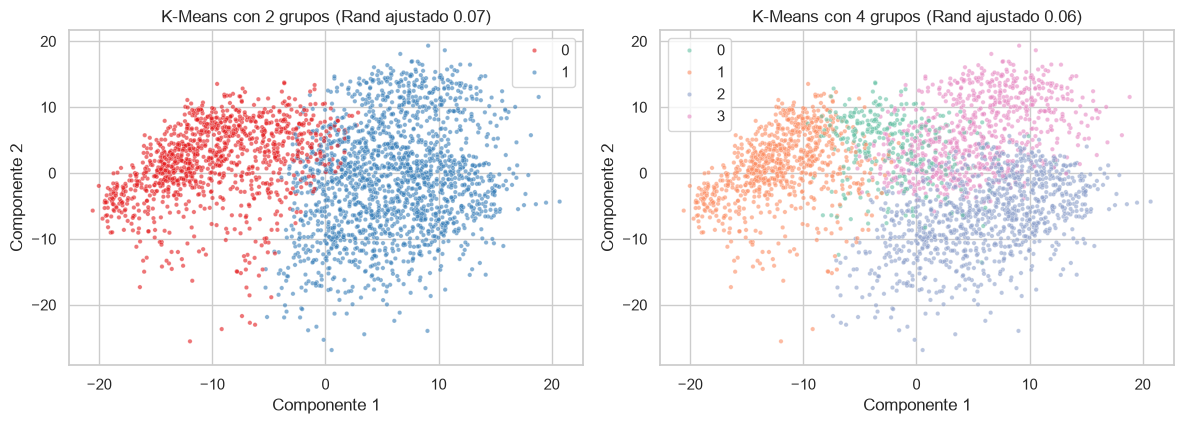

In [4]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=config.SEMILLA).fit(Z)
km4 = KMeans(n_clusters=4, n_init=10, random_state=config.SEMILLA).fit(Z)
tabla2 = pd.crosstab(pd.Series(binaria, name="clase real"), pd.Series(km2.labels_, name="grupo K-Means (k=2)"))
tabla4 = pd.crosstab(pd.Series(nombres.to_numpy(), name="clase real"), pd.Series(km4.labels_, name="grupo K-Means (k=4)"))
ari2 = adjusted_rand_score(man_ent.es_tumor, km2.labels_)
ari4 = adjusted_rand_score(man_ent.clase, km4.labels_)
display(tabla2); print(f"Índice de Rand ajustado (k=2 contra tumor / sin tumor): {ari2:.3f}")
display(tabla4); print(f"Índice de Rand ajustado (k=4 contra las 4 clases): {ari4:.3f}")
tabla2.to_csv(config.RESULTADOS / "kmeans_k2_tabla.csv"); tabla4.to_csv(config.RESULTADOS / "kmeans_k4_tabla.csv")
pd.DataFrame([{"k": 2, "comparado_con": "tumor / sin tumor", "rand_ajustado": ari2},
              {"k": 4, "comparado_con": "4 clases", "rand_ajustado": ari4}]).to_csv(config.RESULTADOS / "kmeans_rand.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km2.labels_, palette="Set1", s=10, alpha=0.6, ax=axs[0]); axs[0].set_title(f"K-Means con 2 grupos (Rand ajustado {ari2:.2f})")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km4.labels_, palette="Set2", s=10, alpha=0.6, ax=axs[1]); axs[1].set_title(f"K-Means con 4 grupos (Rand ajustado {ari4:.2f})")
for ax in axs:
    ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
plt.tight_layout(); plt.savefig(FIGURAS / "rasgos_02_kmeans.png", dpi=130); plt.show()

### Lectura
- Las cifras de arriba son las de esta corrida. Un índice de Rand ajustado cercano a 0 significa que los grupos naturales de los rasgos **no** coinciden con las clases; cercano a 1, que coinciden.
- Que K-Means no recupere las clases no impide que un modelo supervisado las separe: la separación puede estar en direcciones que no son las de mayor varianza.
- PCA y K-Means se usan aquí solo para **entender** los datos. Los modelos del notebook 03 usan los 1,280 rasgos completos.
- La comprobación de fuga entre entrenamiento y prueba (copias, espejos y giros) está al final del notebook 01. No se repite aquí con los rasgos de MobileNetV2 porque esos rasgos **no** son invariantes al espejo: una imagen y su espejo pueden dar rasgos distintos, así que esa medida subestimaría la fuga.

In [5]:
print(f"Notebook terminado en {time.time() - INICIO:.0f} s")

Notebook terminado en 4 s
